![Banner](../images/09_12_surface_energy_balance_modeling.png)

# Net Radiation from Landsat: Albedo, Emissivity and Surface Temperature

Net radiation is the energy available at the surface, the left side of `Rn = G + H + LE`. Every
watt of it that the model gets wrong ends up in the latent heat flux, because LE is the residual.
Fortunately net radiation is the best constrained term: it follows from the sun's position, the
clearness of the sky, how much sunlight the surface reflects (albedo) and how much longwave it
emits (emissivity and temperature). This notebook builds each component for the 5 July 2024
Landsat 8 scene: land surface temperature from the thermal radiance, broadband albedo from six
reflective bands (checked against MODIS), clear-sky transmissivity and incoming shortwave,
emissivity from LAI, and incoming and outgoing longwave, and then maps net radiation by crop.

## Overview

### The radiation balance

`Rn = (1 - albedo) Rs_in + RL_in - RL_out - (1 - eps0) RL_in`

| Term | Meaning | How it is estimated |
|---|---|---|
| `Rs_in` | incoming shortwave (sun) | `Gsc cos(theta) dr tau_sw`: solar constant, incidence angle, Earth-Sun distance, transmissivity |
| `albedo` | share of shortwave reflected | weighted sum of surface reflectance bands |
| `RL_in` | incoming longwave (sky) | `eps_a sigma Ta^4`, air emissivity from transmissivity |
| `RL_out` | outgoing longwave (surface) | `eps0 sigma Ts^4` from LST |
| `(1 - eps0) RL_in` | sky longwave reflected by the surface | small, a few W m-2 |

### Broadband albedo

Albedo is reflectance integrated over the whole solar spectrum (0.3 to 3 um) and all directions.
Landsat measures six narrow bands at one view angle, so albedo is a weighted sum of them. The
weights come from radiative transfer simulations: Liang (2001) for many sensors, adapted for OLI
by Smith (2010), and Tasumi et al. (2008) for TM and ETM+, which METRIC uses. They differ because
they assume different spectra of sunlight and surfaces; typical differences are 0.01 to 0.02.

### Shortwave transmissivity

For clear skies, ASCE (2005) and METRIC compute the broadband transmissivity from pressure `P`,
precipitable water `W = 0.14 ea P + 2.1` and the sun angle:

`tau_sw = 0.35 + 0.627 exp(-0.00146 P / (Kt cos theta) - 0.075 (W / cos theta)^0.4)`

with `Kt = 1` for clean air. On sloping ground `cos theta` is replaced by the cosine of the
incidence angle on the slope, which depends on slope, aspect, latitude, declination and hour
angle.

### Land surface temperature from thermal radiance

The thermal sensor measures radiance at the top of the atmosphere, `L_sensor`. Part of it comes
from the atmosphere itself (upwelled radiance `Lu`), part is sky radiance reflected by the surface
(`(1 - eps) Ld`), and the surface emission is attenuated by the transmissivity `tau`:

`L_sensor = tau eps B(Ts) + tau (1 - eps) Ld + Lu`

Solving for the surface emission and inverting Planck's law with the band constants `K1` and
`K2` (from the scene's MTL file) gives LST:

`B(Ts) = (L_sensor - Lu - tau (1 - eps) Ld) / (tau eps)`, `Ts = K2 / ln(K1 / B(Ts) + 1)`

The Collection 2 Level-2 product delivers every term of this equation (`ST_TRAD`, `ST_URAD`,
`ST_DRAD`, `ST_ATRAN`, `ST_EMIS`), computed from a reanalysis atmospheric profile with MODTRAN and
ASTER emissivity, together with the resulting `ST_B10`.

### Emissivity

Broadband emissivity `eps0` (for longwave emission) and narrowband emissivity (for the thermal
band) both rise from about 0.95 to 0.98 with leaf area. METRIC uses `eps0 = 0.95 + 0.01 LAI` for
LAI up to 3 (Tasumi 2003) and 0.985 for water.

## The Radiation Balance with GeoLattice

| Function | Purpose |
|---|---|
| `seb.albedo(sr, sensor=)` | broadband albedo (`landsat8`, `tasumi`, `sentinel2`, `modis` weights) |
| `seb.savi`, `seb.leaf_area_index`, `seb.surface_emissivity` | LAI and emissivity |
| `seb.broadband_transmissivity`, `seb.incoming_shortwave`, `seb.cos_incidence` | incoming shortwave |
| `seb.air_emissivity`, `seb.incoming_longwave`, `seb.outgoing_longwave` | longwave terms |
| `seb.net_radiation` | the balance |
| `geolattice.rsense.optical.lst` | brightness temperature and single-channel LST |

### Learning objectives

1. Retrieve LST from Landsat thermal radiance with the atmospheric terms of Collection 2, and see
   what the atmospheric correction changes.
2. Compute broadband albedo with two sets of weights and check it against MODIS.
3. Compute clear-sky transmissivity and incoming shortwave, and compare with ERA5.
4. Estimate LAI and emissivity, and the longwave terms.
5. Map net radiation and explain its pattern across crops and fallow land.

### Data

| Dataset | Content |
|---|---|
| Landsat 8 C2 L2, 5 July 2024 | reflectance, `ST_B10`, and the thermal radiance terms, cached by `sd.load_scene` |
| Scene MTL file | thermal constants `K1`, `K2` of band 10 |
| MODIS MCD43A4, day 187 of 2024 | 500 m nadir BRDF-adjusted reflectance, tile h08v05 |
| ERA5 at the overpass | air temperature, humidity and measured shortwave |

### Contents

- Setup
- Land surface temperature from thermal radiance
- Broadband albedo
- Albedo against MODIS
- Transmissivity and incoming shortwave
- LAI and emissivity
- Longwave radiation
- Net radiation
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

import requests  # the MTL file
from geolattice.rsense.optical import lst as lstmod  # brightness temperature and single-channel LST

ds = sd.load_scene()  # Landsat 8, 5 July 2024
m = ds.clear.astype(bool) & (ds.water == 0)  # clear land pixels
a = ds.attrs  # overpass weather and geometry
ext = [float(ds.x.min()), float(ds.x.max()), float(ds.y.min()), float(ds.y.max())]  # map extent
GROUPS = {"Tree crops": [75, 204, 76, 211, 212, 217], "Grapes": [69], "Annual crops": [54, 2, 1, 36, 208, 24, 21, 51],
          "Fallow": [61], "Grass and shrubs": [176, 152], "Developed": [121, 122, 123, 124]}  # CDL codes per group


def by_group(**layers):  # mean of each layer per crop group
    df = xr.Dataset(layers).assign(cdl=ds.cdl).to_dataframe().dropna()  # one row per pixel
    out = {g: df[df.cdl.isin(c)].drop(columns=["cdl", "spatial_ref"], errors="ignore").mean() for g, c in GROUPS.items()}  # group means
    return pd.DataFrame(out).T  # one row per group

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


## Land surface temperature from thermal radiance

The thermal constants of band 10 come from the scene's MTL file. With them and the atmospheric
terms of Collection 2, the radiative transfer equation of the Overview gives LST.

In [2]:
item = sd.landsat_item(sd.MAIN_SCENE)  # STAC item
mtl = requests.get(item.assets["mtl.json"].href, timeout=60).json()["LANDSAT_METADATA_FILE"]  # metadata
K1 = float(mtl["LEVEL1_THERMAL_CONSTANTS"]["K1_CONSTANT_BAND_10"])  # W m-2 sr-1 um-1
K2 = float(mtl["LEVEL1_THERMAL_CONSTANTS"]["K2_CONSTANT_BAND_10"])  # K
print(f"band 10: K1 = {K1}, K2 = {K2}")  # constants

L, tau, Lu, Ld, eps = ds.trad, ds.atran, ds.urad, ds.drad, ds.emis  # radiance terms from Collection 2
B = (L - Lu - tau * (1 - eps) * Ld) / (tau * eps)  # surface-leaving blackbody radiance
lst_rt = (K2 / np.log(K1 / B + 1)).where(m)  # LST by radiative transfer, K
bt = (K2 / np.log(K1 / L + 1)).where(m)  # top-of-atmosphere brightness temperature, K
lst_sc = lstmod.lst_single_channel(bt, lstmod.emissivity_ndvi(seb.ndvi(ds.red, ds.nir)),
                                   wavelength=lstmod.WAVELENGTH["landsat8_b10"])  # emissivity only, no atmosphere
st = ds.lst.where(m)  # Collection 2 ST_B10
print(f"atmosphere at the overpass: tau {float(tau.mean()):.3f}, Lu {float(Lu.mean()):.2f}, Ld {float(Ld.mean()):.2f} W m-2 sr-1 um-1")  # atmosphere
pd.DataFrame({"median (C)": [float(v.median()) - 273.15 for v in (bt, lst_sc, lst_rt, st)],  # medians
              "minus ST_B10, median (K)": [float((v - st).median()) for v in (bt, lst_sc, lst_rt, st)],  # bias against the product
              "minus ST_B10, 95th pct of |diff| (K)": [float(np.abs(v - st).quantile(0.95)) for v in (bt, lst_sc, lst_rt, st)]},  # spread
             index=["brightness temperature", "emissivity correction only", "radiative transfer (this notebook)", "Collection 2 ST_B10"]).round(2)  # table

band 10: K1 = 774.8853, K2 = 1321.0789
atmosphere at the overpass: tau 0.834, Lu 1.45, Ld 0.71 W m-2 sr-1 um-1


,median (C),"minus ST_B10, median (K)","minus ST_B10, 95th pct of |diff| (K)"
brightness temperature,44.65,-6.51,7.94
emissivity correction only,46.55,-4.77,5.71
radiative transfer (this notebook),51.28,0.13,0.14
Collection 2 ST_B10,51.15,0.00,0.00


The radiative transfer result reproduces `ST_B10` within 0.15 K (the rest is rounding of the
stored integers and the USGS implementation). The raw brightness temperature is 6.5 K too cold.
Correcting for emissivity alone recovers less than 2 K of that; the other 4.8 K is the
atmosphere, which absorbs 17 % of the surface signal (`tau` 0.83) and adds its own, colder,
emission. Errors of that size matter: in the hot anchor, 1 K of LST changes
`H` by about 15 to 20 W m-2. The chapter uses `ST_B10`.

## Broadband albedo

`seb.albedo` accepts a Dataset of reflectance bands named `blue, green, red, nir, swir16, swir22`
and applies a chosen set of weights.

weights: {'landsat8': ({'blue': 0.356, 'red': 0.13, 'nir': 0.373, 'swir16': 0.085, 'swir22': 0.072}, -0.0018), 'tasumi': ({'blue': 0.254, 'green': 0.149, 'red': 0.147, 'nir': 0.311, 'swir16': 0.103, 'swir22': 0.036}, 0.0)}


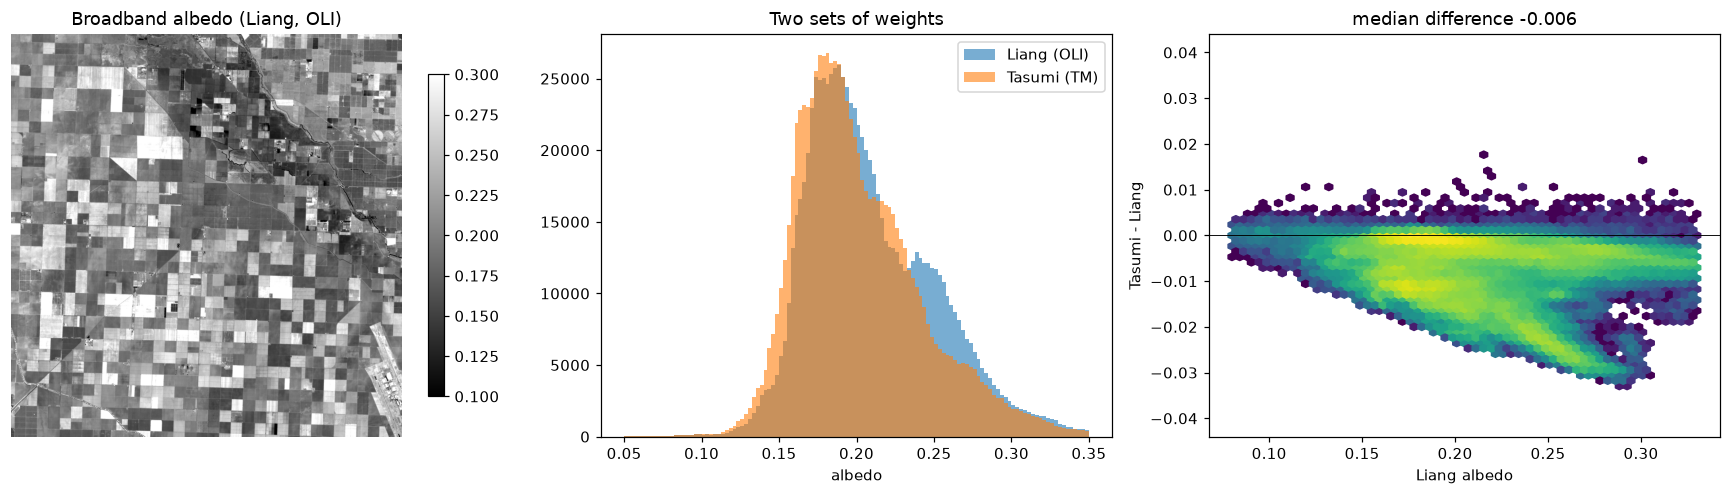

,albedo,ndvi
Tree crops,0.184,0.466
Grapes,0.222,0.604
Annual crops,0.238,0.482
Fallow,0.196,0.127
Grass and shrubs,0.217,0.223
Developed,0.212,0.211


In [3]:
sr = ds[list(sd.REFLECTANCE)].where(m)  # six reflectance bands
alb_liang = seb.albedo(sr, sensor="landsat8")  # Liang (2001) weights for OLI (no green band)
alb_tasumi = seb.albedo(sr, sensor="tasumi")  # Tasumi et al. (2008), TM/ETM+ bands mapped to OLI
print("weights:", {k: seb.ALBEDO_WEIGHTS[k] for k in ("landsat8", "tasumi")})  # the two sets of weights
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))  # three panels
im = ax[0].imshow(alb_liang, extent=ext, cmap="gray", vmin=0.1, vmax=0.3); plt.colorbar(im, ax=ax[0], shrink=0.8)  # albedo map
ax[0].set_title("Broadband albedo (Liang, OLI)"); ax[0].axis("off")  # title
ax[1].hist(alb_liang.values.ravel(), bins=120, range=(0.05, 0.35), alpha=0.6, label="Liang (OLI)")  # distribution
ax[1].hist(alb_tasumi.values.ravel(), bins=120, range=(0.05, 0.35), alpha=0.6, label="Tasumi (TM)")  # distribution
ax[1].legend(); ax[1].set_xlabel("albedo"); ax[1].set_title("Two sets of weights")  # labels
ax[2].hexbin(alb_liang.values.ravel(), (alb_tasumi - alb_liang).values.ravel(), gridsize=60, bins="log", extent=(0.08, 0.33, -0.04, 0.04))  # difference
ax[2].axhline(0, color="k", lw=0.6); ax[2].set_xlabel("Liang albedo"); ax[2].set_ylabel("Tasumi - Liang")  # labels
ax[2].set_title(f"median difference {float((alb_tasumi - alb_liang).median()):+.3f}")  # title
plt.tight_layout(); plt.show()  # draw
by_group(albedo=alb_liang, ndvi=seb.ndvi(sr.red, sr.nir)).round(3)  # albedo per crop group

Albedo ranges from about 0.15 to 0.30. Group means differ less than one might expect: orchards
are darkest (0.18, with shade between the tree rows), fallow land is 0.20 (many fields are
recently tilled, darker soil), and the annual crop group is brightest (0.24; it includes
harvested wheat stubble and the bright canopies of tomatoes and cotton). The Tasumi weights give
albedo 0.006 lower in the median and up to 0.03 lower for bright surfaces, up to about 30 W m-2
of absorbed shortwave at this sun angle.

## Albedo against MODIS

MODIS MCD43A4 provides nadir BRDF-adjusted reflectance at 500 m, a daily product fitted from 16
days of observations. Liang's MODIS weights turn it into broadband albedo, and the Landsat albedo
averaged over each MODIS pixel gives a scale-matched comparison.

3373 cells of 480 m: bias -0.004, RMSE 0.018, R2 0.76


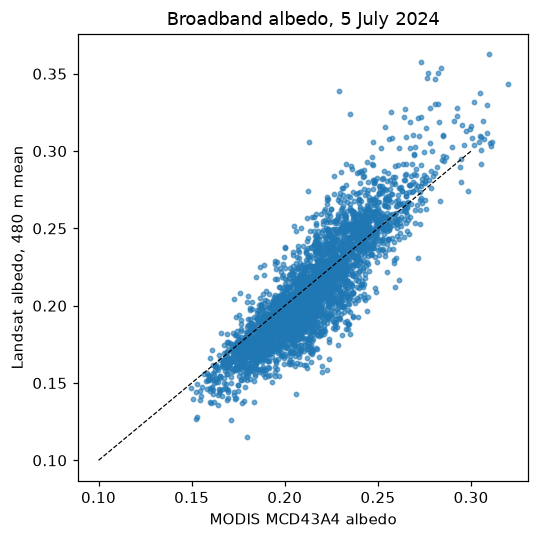

In [4]:
from rasterio.enums import Resampling  # resampling methods

cat = sd._catalog()  # Planetary Computer
it = list(cat.search(collections=["modis-43A4-061"], bbox=sd.WESTSIDE["bbox"], datetime="2024-07-05").items())[0]  # day 187 tile
names = {1: "red", 2: "nir", 3: "blue", 4: "green", 5: "swir12", 7: "swir22"}  # MODIS band numbers
coarse = alb_liang.rio.write_crs(ds.rio.crs).rio.reproject(ds.rio.crs, resolution=480, resampling=Resampling.average)  # Landsat albedo averaged to 480 m
mod = xr.Dataset({n: rioxarray.open_rasterio(it.assets[f"Nadir_Reflectance_Band{b}"].href).squeeze("band", drop=True)
                  .rio.reproject_match(coarse, resampling=Resampling.bilinear) for b, n in names.items()})  # NBAR on that grid
mod = mod.where(mod < 32767) * 1e-4  # fill value and scale factor
alb_modis = seb.albedo(mod, sensor="modis")  # Liang (2001) MODIS weights
pair = pd.DataFrame({"modis": alb_modis.values.ravel(), "landsat": coarse.values.ravel()}).dropna()  # matched pixels
pair = pair[(pair.landsat > 0) & (pair.modis > 0)]  # valid pairs
stats = seb.compare_to_tower(pair.landsat, pair.modis)  # Landsat against MODIS
print(f"{int(stats.n)} cells of 480 m: bias {stats.bias:+.3f}, RMSE {stats.rmse:.3f}, R2 {stats.r2:.2f}")  # agreement
fig, ax = plt.subplots(figsize=(5, 5)); ax.scatter(pair.modis, pair.landsat, s=8, alpha=0.6)  # scatter
ax.plot([0.1, 0.3], [0.1, 0.3], "k--", lw=0.8); ax.set_xlabel("MODIS MCD43A4 albedo"); ax.set_ylabel("Landsat albedo, 480 m mean")  # 1:1 line
ax.set_title("Broadband albedo, 5 July 2024"); plt.tight_layout(); plt.show()  # draw

The two sensors agree closely on the spatial pattern, with a small offset between them. Exact
agreement is not expected: MCD43A4 is nadir reflectance at local solar noon from a 16 day fit, the
Landsat image is one view at 11:33, and the two use different weights. The check rules out gross
errors such as a missing scale offset or a wrong band order.

## Transmissivity and incoming shortwave

Pressure comes from the DEM, vapour pressure from the ERA5 dew point at the overpass, and the sun
angle from the metadata. On flat ground `cos theta` is the cosine of the solar zenith angle.

In [5]:
pressure = seb.pressure_from_elevation(ds.dem)  # kPa
cos_z = float(np.cos(np.radians(90 - a["sun_elevation"])))  # flat ground
tau_sw = seb.broadband_transmissivity(cos_z, pressure=pressure, ea=a["ea_kpa"])  # clear-sky transmissivity
rs_in = seb.incoming_shortwave(cos_z, tau_sw, dr=a["dr"])  # W/m2
slope, aspect = seb.slope_aspect(ds.dem)  # terrain
cos_t = seb.cos_incidence(sd.WESTSIDE["lat"], pd.Timestamp(a["datetime"]), sd.WESTSIDE["lon"], slope, aspect)  # on the slopes
rs_slope = seb.incoming_shortwave(cos_t, tau_sw, dr=a["dr"])  # W/m2 with terrain
print(f"precipitable water {float(seb.precipitable_water(a['ea_kpa'], pressure.mean())):.1f} mm | tau_sw {float(tau_sw.mean()):.3f}")  # atmosphere
print(f"Rs_in, clear-sky model: {float(rs_in.mean()):.0f} W/m2 (flat), {float(rs_slope.min()):.0f} to {float(rs_slope.max()):.0f} W/m2 with terrain")  # model
print(f"pixels the terrain correction changes by more than 10 W/m2: {float((np.abs(rs_slope - rs_in) > 10).mean()):.1%}")  # how many matter
print(f"Rs_in, ERA5 at the overpass: {a['rs_wm2']:.0f} W/m2")  # reanalysis

precipitable water 11.9 mm | tau_sw 0.784
Rs_in, clear-sky model: 950 W/m2 (flat), 788 to 1024 W/m2 with terrain
pixels the terrain correction changes by more than 10 W/m2: 1.1%
Rs_in, ERA5 at the overpass: 854 W/m2


On this valley floor the terrain correction changes only 1.1 % of pixels by more than 10 W m-2. Its extremes
(about 790 to 1,020 W m-2) come from canal banks, road embankments and noise in the 30 m DEM, a
few pixels with slopes of a few degrees; the chapter therefore uses flat-ground radiation for the
Westside scenes, while the hill-slope correction matters in mountain valleys. The clear-sky model gives about 950 W m-2, roughly 10 % more than ERA5's value interpolated to the
overpass. ERA5 averages over each hour and over a 25 km cell that includes hazier foothill air, so
a gap of this size on a cloudless day is typical; the METRIC clear-sky formula is used for the
instantaneous balance because it is computed for the exact time and place.

## LAI and emissivity

METRIC estimates LAI from SAVI with an empirical curve from southern Idaho crops (Allen et al.
2002), using the soil adjustment `L = 0.1` from that calibration, and emissivity from LAI.

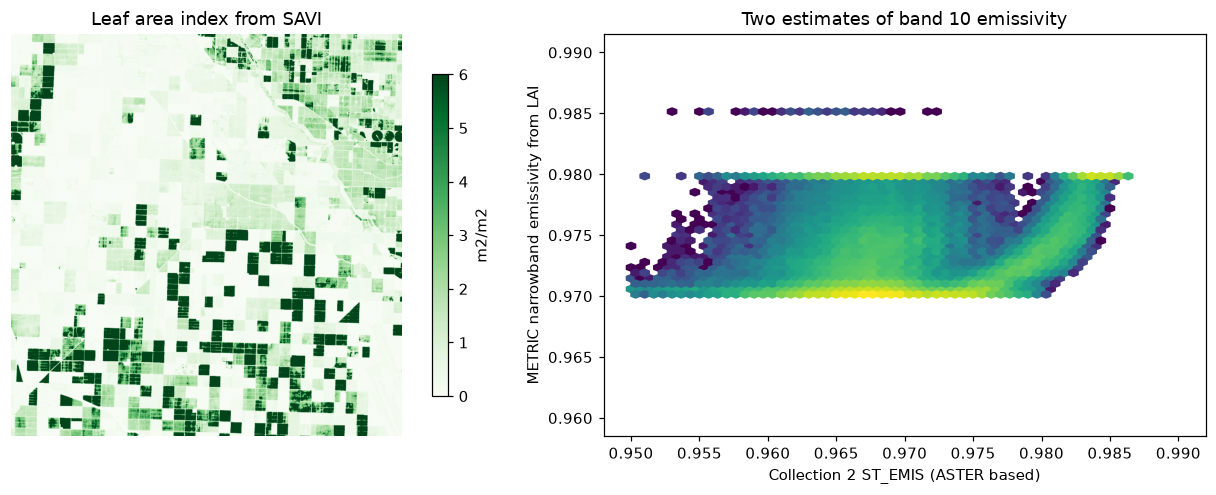

,lai,eps0,st_emis
Tree crops,1.201,0.961,0.971
Grapes,2.344,0.968,0.975
Annual crops,2.413,0.965,0.971
Fallow,0.036,0.950,0.969
Grass and shrubs,0.218,0.952,0.966
Developed,0.237,0.952,0.967


In [6]:
savi = seb.savi(sr.red, sr.nir, L=0.1)  # SAVI with L = 0.1 (METRIC)
lai = seb.leaf_area_index(savi)  # m2/m2, capped at 6
e0 = seb.surface_emissivity(lai, seb.ndvi(sr.red, sr.nir))  # broadband, for longwave
e_nb = seb.surface_emissivity(lai, seb.ndvi(sr.red, sr.nir), kind="narrowband")  # band 10
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))  # two panels
im = ax[0].imshow(lai, extent=ext, cmap="Greens", vmin=0, vmax=6); plt.colorbar(im, ax=ax[0], shrink=0.8, label="m2/m2")  # LAI map
ax[0].set_title("Leaf area index from SAVI"); ax[0].axis("off")  # title
ax[1].hexbin(ds.emis.where(m).values.ravel(), e_nb.values.ravel(), gridsize=60, bins="log", extent=(0.95, 0.99, 0.96, 0.99))  # band emissivity
ax[1].set_xlabel("Collection 2 ST_EMIS (ASTER based)"); ax[1].set_ylabel("METRIC narrowband emissivity from LAI")  # labels
ax[1].set_title("Two estimates of band 10 emissivity"); plt.tight_layout(); plt.show()  # draw
by_group(lai=lai, eps0=e0, st_emis=ds.emis.where(m)).round(3)  # per crop group

LAI tracks the crop pattern: dense fields reach the cap of 6, the group means are about 2.4 for
annual crops and grapes and 1.2 for orchards (young plantings and bare rows between the trees),
and fallow land is near 0. The two emissivity estimates agree on the range but not pixel by pixel:
`ST_EMIS` adjusts a multi-year ASTER emissivity with the NDVI of the day, while the METRIC curve
uses LAI alone, and it is lower over bare soil (0.95 against about 0.97). A difference of 0.01
in emissivity changes outgoing longwave by about 6 W m-2 at
330 K.

## Longwave radiation

Outgoing longwave follows from LST and broadband emissivity. Incoming longwave needs the air
temperature near the surface; METRIC takes the LST of the cold anchor as a surrogate (a well
watered crop is close to air temperature) and the air emissivity from transmissivity,
`eps_a = 0.85 (-ln tau_sw)^0.09`. The Brutsaert (1975) formula with ERA5 air temperature and
humidity is an independent estimate.

In [7]:
anchors = seb.select_anchors(seb.ndvi(sr.red, sr.nir), st, albedo_=alb_liang, mask=m)  # cold and hot pixels (notebook 05)
t_cold = anchors["cold"]["lst"]  # K
tau_c = float(tau_sw.values[anchors["cold"]["iy"], anchors["cold"]["ix"]])  # transmissivity at the cold pixel
rl_in = seb.incoming_longwave(t_cold, seb.air_emissivity(tau_sw=tau_c))  # METRIC, W/m2
rl_in_b = seb.incoming_longwave(a["t_air_c"] + 273.15, seb.air_emissivity(ea=a["ea_kpa"], t_air_k=a["t_air_c"] + 273.15))  # Brutsaert with ERA5
rl_out = seb.outgoing_longwave(st, e0)  # W/m2
print(f"cold anchor LST {t_cold - 273.15:.1f} C, ERA5 air {a['t_air_c']:.1f} C")  # the two air temperature surrogates
print(f"RL_in: METRIC {float(rl_in):.0f} W/m2, Brutsaert with ERA5 {float(rl_in_b):.0f} W/m2")  # incoming longwave
print(f"RL_out: {float(rl_out.quantile(0.02)):.0f} to {float(rl_out.quantile(0.98)):.0f} W/m2 (2nd to 98th percentile)")  # outgoing longwave

cold anchor LST 35.2 C, ERA5 air 39.8 C
RL_in: METRIC 384 W/m2, Brutsaert with ERA5 392 W/m2
RL_out: 510 to 665 W/m2 (2nd to 98th percentile)


The two estimates of incoming longwave are within 8 W m-2 (384 and 392): the cold anchor (a well
watered almond orchard at 35.2 C) is 4.6 K cooler than the ERA5 air, and the transmissivity-based
air emissivity makes up most of that difference. Outgoing longwave varies
across the scene by about 150 W m-2, almost all of it from LST: hot fallow fields lose far more
energy as longwave than cool crops.

## Net radiation

Rn 392 to 645 W/m2 (median 524); largest difference from sd.energy_inputs: 0.00e+00


,Rs_in,reflected,RL_in,RL_out,RL_reflected,Rn
Tree crops,950.0,-175.0,384.0,-578.0,-15.0,566.0
Grapes,950.0,-211.0,384.0,-557.0,-12.0,554.0
Annual crops,950.0,-226.0,384.0,-575.0,-14.0,519.0
Fallow,950.0,-186.0,384.0,-645.0,-19.0,484.0
Grass and shrubs,950.0,-206.0,384.0,-632.0,-18.0,478.0
Developed,950.0,-201.0,384.0,-613.0,-18.0,501.0


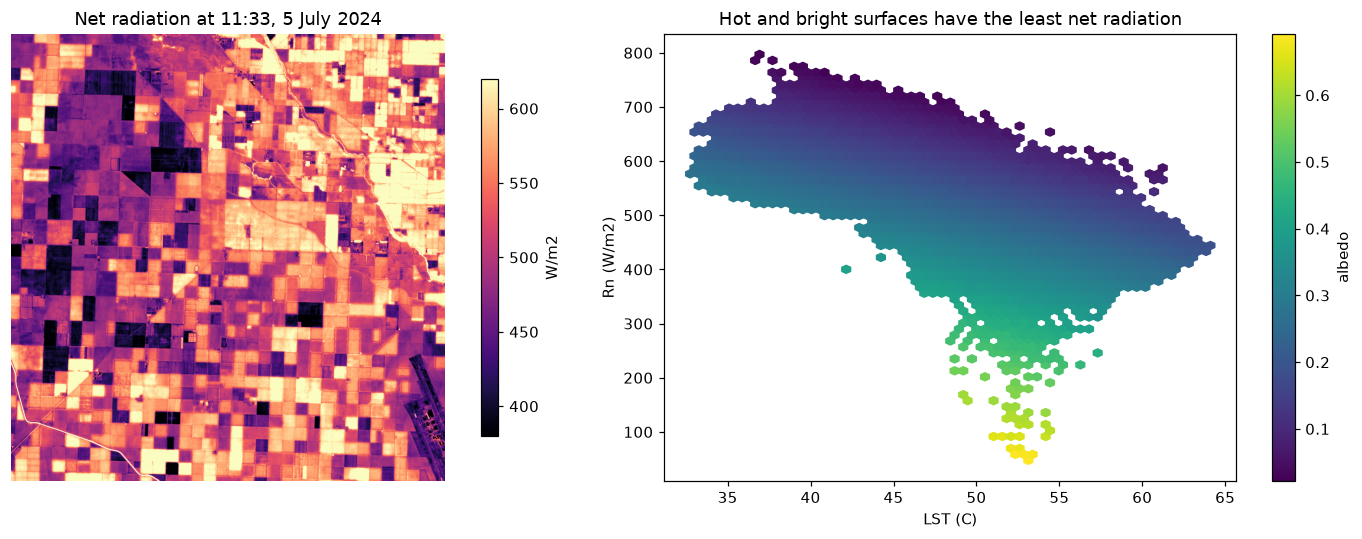

In [8]:
rn = seb.net_radiation(rs_in, alb_liang, rl_in, rl_out, e0)  # W/m2
check = sd.energy_inputs(ds)["rn"]  # the same chain in the chapter helper
print(f"Rn {float(rn.quantile(0.02)):.0f} to {float(rn.quantile(0.98)):.0f} W/m2 (median {float(rn.median()):.0f}); "
      f"largest difference from sd.energy_inputs: {float(np.nanmax(np.abs(rn - check))):.2e}")  # range and check
parts = by_group(Rs_in=rs_in + 0 * st, reflected=-alb_liang * rs_in, RL_in=rl_in + 0 * st, RL_out=-rl_out,
                 RL_reflected=-(1 - e0) * rl_in, Rn=rn)  # components per group
display(parts.round(0))  # W/m2
fig, ax = plt.subplots(1, 2, figsize=(14, 5))  # map and scatter
im = ax[0].imshow(rn, extent=ext, cmap="magma", vmin=380, vmax=620); plt.colorbar(im, ax=ax[0], shrink=0.8, label="W/m2")  # Rn map
ax[0].set_title("Net radiation at 11:33, 5 July 2024"); ax[0].axis("off")  # title
h = ax[1].hexbin((st - 273.15).values.ravel(), rn.values.ravel(), C=alb_liang.values.ravel(), gridsize=60, cmap="viridis")  # Rn vs LST, coloured by albedo
plt.colorbar(h, ax=ax[1], label="albedo"); ax[1].set_xlabel("LST (C)"); ax[1].set_ylabel("Rn (W/m2)")  # labels
ax[1].set_title("Hot and bright surfaces have the least net radiation"); plt.tight_layout(); plt.show()  # draw

Net radiation is highest over orchards and vineyards (566 and 554 W m-2) and lowest over fallow
land and rangeland (484 and 478 W m-2). The component table shows why: the groups reflect
similar amounts of sunlight, but hot fallow land emits about 70 W m-2 more longwave than the
cool orchards. The difference of about 80 W m-2 is a substantial share of what is available for
ET. Within the crops, the
spread of net radiation is small compared with the spread of `H` and `LE` that the next notebooks
find, which is why the accuracy of the models depends mostly on `H`.

## Summary and exercises

- Radiative transfer with the Collection 2 atmospheric terms reproduces `ST_B10` within 0.15 K;
  the uncorrected brightness temperature is 6.5 K too cold.
- Broadband albedo from OLI bands with Liang's weights ranges from about 0.15 to 0.30, agrees
  with MODIS MCD43A4 at 480 m (bias -0.004, RMSE 0.018, R2 0.76), and is 0.006 higher than the
  Tasumi weights in the median.
- Clear-sky incoming shortwave at the overpass was about 950 W m-2; ERA5's hourly value was about
  10 % lower.
- METRIC's incoming longwave (cold anchor LST and transmissivity) agrees with Brutsaert's formula
  and ERA5.
- Net radiation follows LST more than albedo here: orchards and vineyards had about 80 W m-2
  more net radiation than fallow land, mostly because they emit less longwave.

**Exercises**

1. Recompute LST by radiative transfer with the METRIC narrowband emissivity instead of
   `ST_EMIS`. How large are the differences over fallow land?
2. Replace the Liang albedo with the Tasumi albedo in `Rn`. What is the mean change in W m-2,
   and in daily ET if it all went to LE?
3. Compute `Rn` for the 8 April scene. How does it compare with July, and which term changes most?
4. Use `seb.cos_incidence` to compute incoming shortwave for a 15 degree south-facing slope and a
   15 degree north-facing slope at this overpass time.